In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [2]:
#connect to duckdb
con = duckdb.connect("../Data/duckdb/olist.duckdb")

#Load CSV & Create Views
con.read_csv("../Data/Processed/orders_clean.csv").create_view("orders");

### Order Status Analysis

In [3]:
# Calculate the total number of orders
total = con.sql(""" 
    select count(*) as total
    from orders
 """).df()

print(f"Total orders: {total.iloc[0, 0]}")

Total orders: 99441


In [4]:
#check order status of orders
order_status = con.sql(""" 
        select order_status,
                count(*) as status_number,
                count(*) * 100.0 / sum(count(*)) over () as status_percent
        from orders
        group by order_status
        order by status_number desc;
 """).df()

print("number of each order_status:")
display(order_status)

number of each order_status:


,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


In [5]:
con.close()

In [6]:
#reconnect to duckdb
con = duckdb.connect("../Data/duckdb/olist.duckdb")

In [7]:
order_status

,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


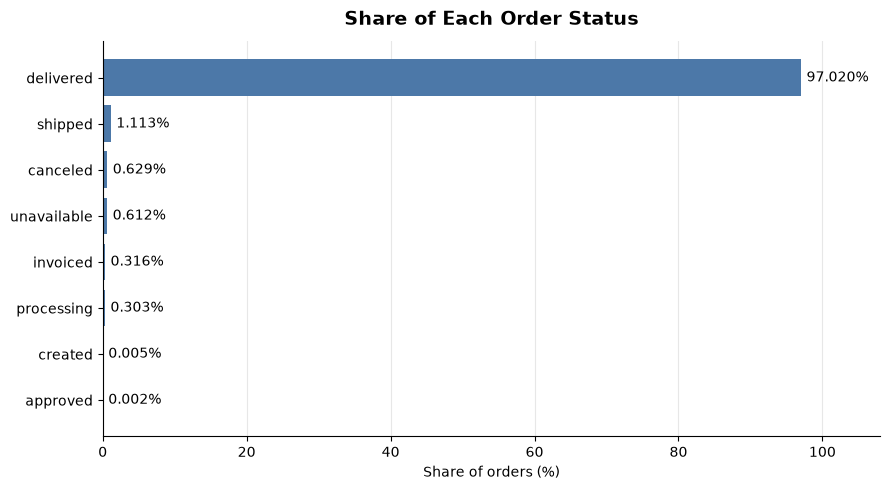

In [8]:
#visualizing chart
plot_df = order_status.sort_values("status_percent", ascending=True)  # ascending=True puts the largest bar on top

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_df["order_status"], plot_df["status_percent"], color="#4C78A8")

ax.bar_label(bars, fmt="%.3f%%", padding=4, fontsize=10)

ax.set_title("Share of Each Order Status", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Share of orders (%)")
ax.set_ylabel("")
ax.set_xlim(0, 108)  # room so the 97.02% label isn't cut off
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Order Status Analysis – Conclusion

The Olist dataset contains **99,441 orders**, of which **97.02% (96,478)** were successfully delivered. Only **0.63%** were canceled, indicating a relatively low cancellation rate.

The remaining orders were distributed across other statuses, including shipped, unavailable, invoiced, and processing.

**Business Insight:**

Overall, Olist demonstrates a high order fulfillment rate and a relatively low cancellation rate. However, further investigation of non-delivered orders is needed to identify potential operational issues.

### Monthly Order Analysis

In [ ]:
monthly_order = con.sql(""" 
    select order_month,
            order_year,
            count(*) as orders_count
    from orders
    group by order_year, order_month
    order by order_year ,order_month
""").df()

#set month name
monthly_order["order_month_name"] = pd.to_datetime(monthly_order['order_month'], format='%m').dt.month_name()

# Real date column, so months sort and plot chronologically
monthly_order["month_start"] = pd.to_datetime(
    dict(year=monthly_order["order_year"], month=monthly_order["order_month"], day=1)
)

print("number of orders for each month:")
display(monthly_order[["month_start","order_month_name","orders_count"]])


number of orders for each month


,month_start,order_month_name,orders_count
0,2016-09-01,September,4
1,2016-10-01,October,324
2,2016-12-01,December,1
3,2017-01-01,January,800
4,2017-02-01,February,1780
5,2017-03-01,March,2682
6,2017-04-01,April,2404
7,2017-05-01,May,3700
8,2017-06-01,June,3245
9,2017-07-01,July,4026


In [40]:
# Valid analysis window 
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   # last valid month (month-start date)

# Fill missing months (e.g. Nov 2016 has no row) with 0 so the line doesn't skip them
full_range = pd.date_range(monthly_order["month_start"].min(),
                           monthly_order["month_start"].max(), freq="MS")
timeline = (monthly_order.set_index("month_start")["orders_count"]
            .reindex(full_range, fill_value=0))

In [45]:
#valid range information
valid = timeline[START:END]

max_date, max_val = valid.idxmax(), valid.max()
min_date, min_val = valid.idxmin(), valid.min()

print("number of orders in valid range date:")
display(valid.to_frame())
print(f"month with the most orders  : {max_date.strftime('%B %Y')} with {max_val:,} orders")
print(f"month with the fewest orders: {min_date.strftime('%B %Y')} with {min_val:,} orders")


number of orders in valid range date:


,orders_count
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700
2017-06-01,3245
2017-07-01,4026
2017-08-01,4331
2017-09-01,4285
2017-10-01,4631


month with the most orders  : November 2017 with 7,544 orders
month with the fewest orders: January 2017 with 800 orders


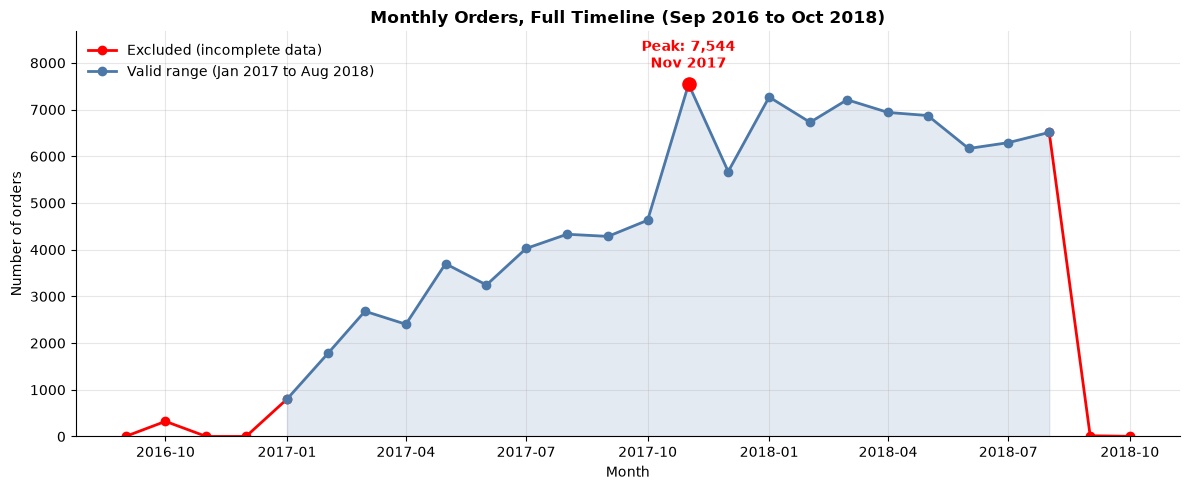

In [ ]:
#Monthly Orders, Full Timeline chart
fig, ax = plt.subplots(figsize=(12, 5))

# Split the timeline into three parts
# (slicing is inclusive on both ends, so the boundary month is shared and the lines connect)
left_excluded  = timeline[:START]    # Sep 2016 to Jan 2017
valid          = timeline[START:END] # Jan 2017 to Aug 2018
right_excluded = timeline[END:]      # Aug 2018 to Oct 2018

# Excluded parts in red
ax.plot(left_excluded.index, left_excluded.values,
        marker="o", color="red", linewidth=2, label="Excluded (incomplete data)")
ax.plot(right_excluded.index, right_excluded.values,
        marker="o", color="red", linewidth=2)

# Valid window in blue, drawn on top so the shared boundary points stay blue
ax.plot(valid.index, valid.values,
        marker="o", color="#4C78A8", linewidth=2, zorder=3,
        label="Valid range (Jan 2017 to Aug 2018)")

# Light fill under the valid window only
ax.fill_between(valid.index, valid.values, color="#4C78A8", alpha=0.15)

# Peak inside the valid window
peak_date  = valid.idxmax()
peak_value = valid.max()
ax.scatter(peak_date, peak_value, color="red", s=90, zorder=5)
ax.annotate(f"Peak: {peak_value:,}\n{peak_date.strftime('%b %Y')}",
            xy=(peak_date, peak_value),
            xytext=(0, 12), textcoords="offset points",
            ha="center", color="red", fontweight="bold")

ax.set_ylim(0, timeline.max() * 1.15)
ax.set_title("Monthly Orders, Full Timeline (Sep 2016 to Oct 2018)", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()